# Time series forecasting with ARIMA

In this notebook, we demonstrate how to:
- prepare time series data for training an ARIMA time series forecasting model
- implement a simple ARIMA model to forecast the next HORIZON steps ahead (time *t+1* through *t+HORIZON*) in the time series
- evaluate the model


The data in this example is taken from the GEFCom2014 forecasting competition<sup>1</sup>. It consists of 3 years of hourly electricity load and temperature values between 2012 and 2014. The task is to forecast future values of electricity load. In this example, we show how to forecast one time step ahead, using historical load data only.

<sup>1</sup>Tao Hong, Pierre Pinson, Shu Fan, Hamidreza Zareipour, Alberto Troccoli and Rob J. Hyndman, "Probabilistic energy forecasting: Global Energy Forecasting Competition 2014 and beyond", International Journal of Forecasting, vol.32, no.3, pp 896-913, July-September, 2016.

## Install Dependencies
Get started by installing some of the required dependencies. These libraries with their corresponding versions are known to work for the solution:

* `statsmodels == 0.12.2`
* `matplotlib == 3.4.2`
* `scikit-learn == 0.24.2`


In [7]:
!pip install statsmodels


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt
import math

from pandas.plotting import autocorrelation_plot
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from IPython.display import Image

%matplotlib inline
pd.options.display.float_format = '{:,.2f}'.format
np.set_printoptions(precision=2)
warnings.filterwarnings("ignore") # specify to ignore warning messages


In [9]:
dataset_filename = "dataset.csv"
energy = pd.read_csv(dataset_filename)
energy = energy.dropna()

energy['Date'] = pd.to_datetime(energy['Date'], format='%d/%m/%Y')
energy['timestamp'] = energy.apply(lambda row: row['Date'] + pd.Timedelta(hours=row['Hour']), axis=1)

energy.set_index('timestamp', inplace=True)

energy.head(10)

,Date,Hour,load,T
timestamp,,,,
2006-01-01 01:00:00,2006-01-01,1,"3,010.00",22.67
2006-01-01 02:00:00,2006-01-01,2,"2,853.00",20.67
2006-01-01 03:00:00,2006-01-01,3,"2,758.00",21.33
2006-01-01 04:00:00,2006-01-01,4,"2,705.00",19.00
2006-01-01 05:00:00,2006-01-01,5,"2,709.00",19.33
2006-01-01 06:00:00,2006-01-01,6,"2,753.00",18.67
2006-01-01 07:00:00,2006-01-01,7,"2,849.00",18.00
2006-01-01 08:00:00,2006-01-01,8,"3,008.00",17.67
2006-01-01 09:00:00,2006-01-01,9,"3,243.00",19.00


Plot all available load data (January 2012 to Dec 2014)

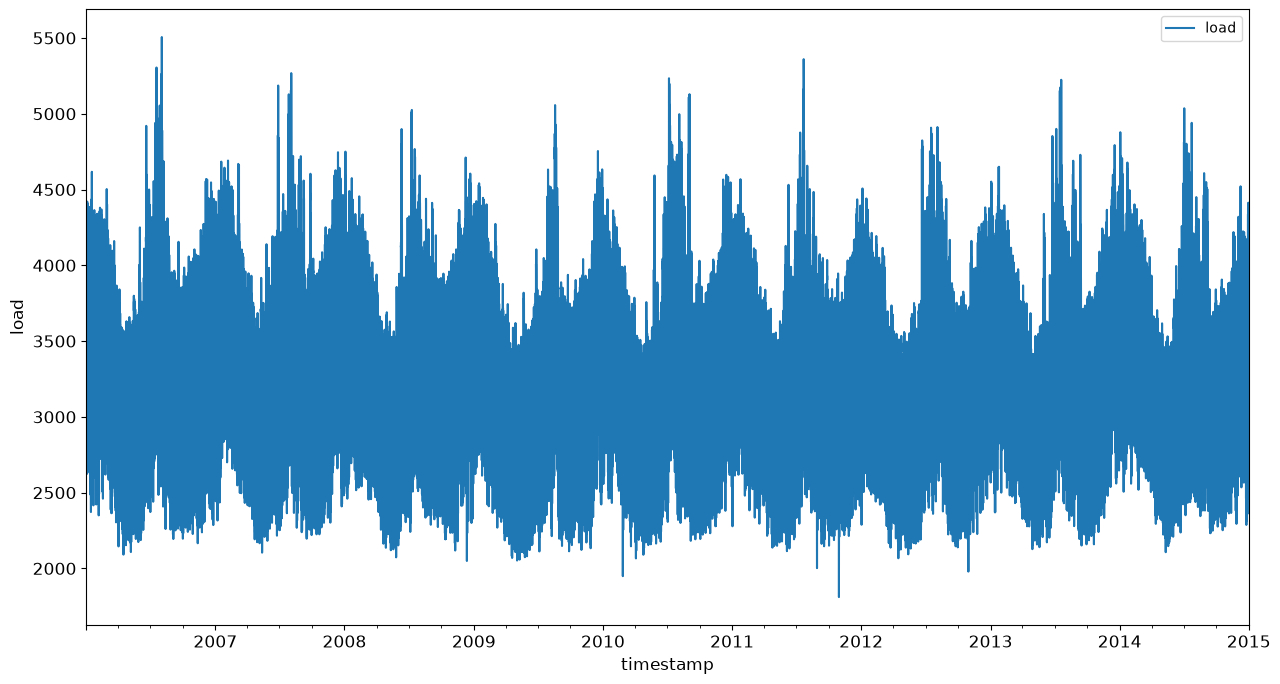

In [10]:
energy.plot(y='load', subplots=True, figsize=(15, 8), fontsize=12)
plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

## Create training and testing data sets


In [11]:
train_start_dt = '2014-11-01 00:00:00'
test_start_dt = '2014-12-30 00:00:00'

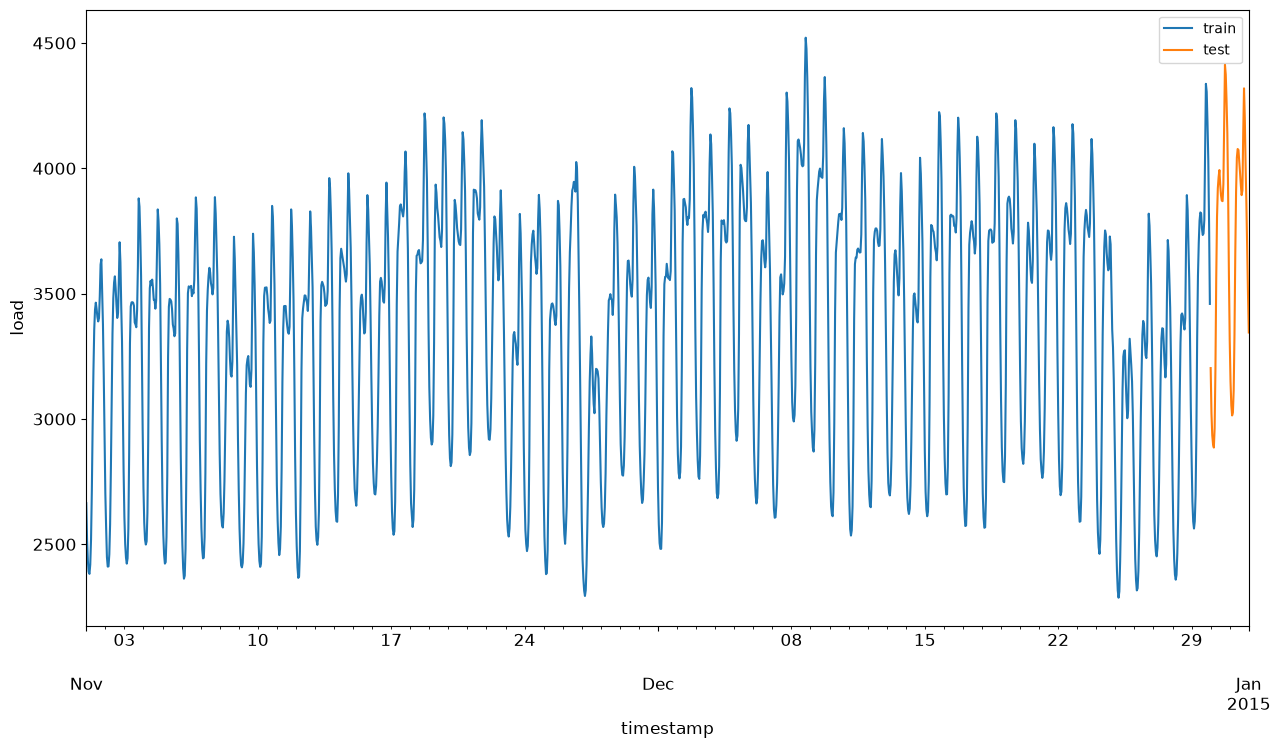

In [12]:
energy[(energy.index < test_start_dt) & (energy.index >= train_start_dt)][['load']].rename(columns={'load':'train'}) \
    .join(energy[test_start_dt:][['load']].rename(columns={'load':'test'}), how='outer') \
    .plot(y=['train', 'test'], figsize=(15, 8), fontsize=12)
plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()

In [13]:
train = energy.copy()[(energy.index >= train_start_dt) & (energy.index < test_start_dt)][['load']]
test = energy.copy()[energy.index >= test_start_dt][['load']]

print('Training data shape: ', train.shape)
print('Test data shape: ', test.shape)

Training data shape:  (1416, 1)
Test data shape:  (49, 1)


In [14]:
scaler = MinMaxScaler()
train['load'] = scaler.fit_transform(train)
train.head(10)

,load
timestamp,
2014-11-01 00:00:00,0.17
2014-11-01 01:00:00,0.10
2014-11-01 02:00:00,0.07
2014-11-01 03:00:00,0.05
2014-11-01 04:00:00,0.04
2014-11-01 05:00:00,0.06
2014-11-01 06:00:00,0.10
2014-11-01 07:00:00,0.19
2014-11-01 08:00:00,0.31


Original vs scaled data:

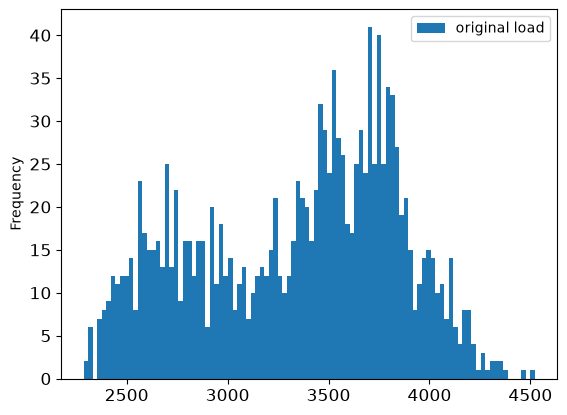

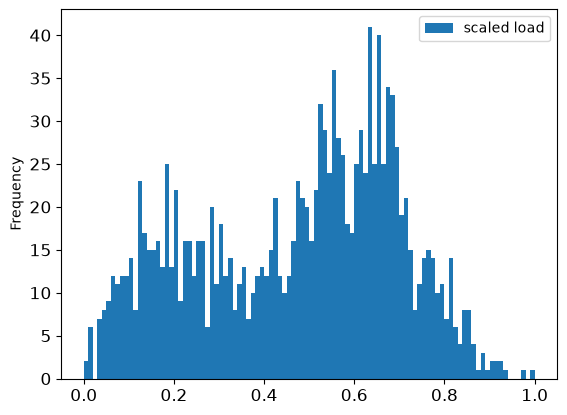

In [15]:
energy[(energy.index >= train_start_dt) & (energy.index < test_start_dt)][['load']].rename(columns={'load':'original load'}).plot.hist(bins=100, fontsize=12)
train.rename(columns={'load':'scaled load'}).plot.hist(bins=100, fontsize=12)
plt.show()

Let's also scale the test data

In [16]:
test['load'] = scaler.transform(test)
test.head()

,load
timestamp,
2014-12-30 00:00:00,0.41
2014-12-30 01:00:00,0.33
2014-12-30 02:00:00,0.29
2014-12-30 03:00:00,0.27
2014-12-30 04:00:00,0.27


## Implement ARIMA method

In [17]:
# Specify the number of steps to forecast ahead
HORIZON = 3
print('Forecasting horizon:', HORIZON, 'hours')

Forecasting horizon: 3 hours


In [18]:
# use 4 previous examples, apply differencing once and use 0 previous errors
order = (4, 1, 0)

# use 1 seasonal AR term, use 1 seasonal differencing, use 0 moving average, cycle repeats after 24 observations
seasonal_order = (1, 1, 0, 24)

model = SARIMAX(endog=train, order=order, seasonal_order=seasonal_order)
results = model.fit()

print(results.summary())

# Takes around 5 minutes!!!

                                     SARIMAX Results                                      
Dep. Variable:                               load   No. Observations:                 1416
Model:             SARIMAX(4, 1, 0)x(1, 1, 0, 24)   Log Likelihood                3476.794
Date:                            Thu, 05 Nov 2026   AIC                          -6941.589
Time:                                    22:02:21   BIC                          -6910.162
Sample:                                11-01-2014   HQIC                         -6929.837
                                     - 12-29-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8388      0.016     52.439      0.000       0.807       0.870
ar.L2         -0.5171      0.034   

## Evaluate the model

Create a test data point for each HORIZON step.

In [20]:
test_shifted = test.copy()

for t in range(1, HORIZON):
    test_shifted['load+'+str(t)] = test_shifted['load'].shift(-t, freq='h')

test_shifted = test_shifted.dropna(how='any')
test_shifted.head(5)

,load,load+1,load+2
timestamp,,,
2014-12-30 00:00:00,0.41,0.33,0.29
2014-12-30 01:00:00,0.33,0.29,0.27
2014-12-30 02:00:00,0.29,0.27,0.27
2014-12-30 03:00:00,0.27,0.27,0.30
2014-12-30 04:00:00,0.27,0.30,0.41


Make predictions on the test data

In [21]:
%%time
training_window = 720 # dedicate 30 days (720 hours) for training

train_ts = train['load']
test_ts = test_shifted

history = [x for x in train_ts]
history = history[(-training_window):]

predictions = list()

# let's user simpler model for demonstration
order = (2, 1, 0)
seasonal_order = (1, 1, 0, 24)

for t in range(test_ts.shape[0]):
    model = SARIMAX(endog=history, order=order, seasonal_order=seasonal_order)
    model_fit = model.fit()
    yhat = model_fit.forecast(steps = HORIZON)
    predictions.append(yhat)
    obs = list(test_ts.iloc[t])
    # move the training window
    history.append(obs[0])
    history.pop(0)
    print(test_ts.index[t])
    print(t+1, ': predicted =', yhat, 'expected =', obs)

2014-12-30 00:00:00
1 : predicted = [0.42 0.34 0.3 ] expected = [0.4100268576544315, 0.32945389435989236, 0.2900626678603402]
2014-12-30 01:00:00
2 : predicted = [0.32 0.29 0.28] expected = [0.32945389435989236, 0.2900626678603402, 0.2739480752014323]
2014-12-30 02:00:00
3 : predicted = [0.3  0.29 0.3 ] expected = [0.2900626678603402, 0.2739480752014323, 0.26812891674127126]
2014-12-30 03:00:00
4 : predicted = [0.27 0.28 0.32] expected = [0.2739480752014323, 0.26812891674127126, 0.3025962399283795]
2014-12-30 04:00:00
5 : predicted = [0.28 0.32 0.42] expected = [0.26812891674127126, 0.3025962399283795, 0.40823634735899716]
2014-12-30 05:00:00
6 : predicted = [0.3  0.39 0.54] expected = [0.3025962399283795, 0.40823634735899716, 0.5689346463742166]
2014-12-30 06:00:00
7 : predicted = [0.4  0.55 0.66] expected = [0.40823634735899716, 0.5689346463742166, 0.6799462846911368]
2014-12-30 07:00:00
8 : predicted = [0.57 0.68 0.75] expected = [0.5689346463742166, 0.6799462846911368, 0.7309758281

Compare predictions to actual load

In [22]:
eval_df = pd.DataFrame(predictions, columns=['t+'+str(t) for t in range(1, HORIZON+1)])
eval_df['timestamp'] = test.index[0:len(test.index)-HORIZON+1]
eval_df = pd.melt(eval_df, id_vars='timestamp', value_name='prediction', var_name='h')
eval_df['actual'] = np.array(np.transpose(test_ts)).ravel()
eval_df[['prediction', 'actual']] = scaler.inverse_transform(eval_df[['prediction', 'actual']])
eval_df.head()

,timestamp,h,prediction,actual
0,2014-12-30 00:00:00,t+1,"3,220.41","3,203.00"
1,2014-12-30 01:00:00,t+1,"3,008.75","3,023.00"
2,2014-12-30 02:00:00,t+1,"2,955.76","2,935.00"
3,2014-12-30 03:00:00,t+1,"2,900.07","2,899.00"
4,2014-12-30 04:00:00,t+1,"2,917.91","2,886.00"


Compute the **mean absolute percentage error (MAPE)** over all predictions

$$MAPE = \frac{1}{n} \sum_{t=1}^{n} \left| \frac{actual_t - predicted_t}{actual_t} \right|$$

In [23]:
if(HORIZON > 1):
    eval_df['APE'] = (eval_df['prediction'] - eval_df['actual']).abs() / eval_df['actual']
    print(eval_df.groupby('h')['APE'].mean())

h
t+1   0.01
t+2   0.01
t+3   0.02
Name: APE, dtype: float64


In [24]:
def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true))

print('One step forecast MAPE: ', (mape(eval_df[eval_df['h'] == 't+1']['prediction'], eval_df[eval_df['h'] == 't+1']['actual']))*100, '')

One step forecast MAPE:  0.5549184367177667 


In [25]:
print('Multi-step forecast MAPE: ', mape(eval_df['prediction'], eval_df['actual']), '')

Multi-step forecast MAPE:  0.011317702754631072 


Plot the predictions vs the actuals for the first week of the test set

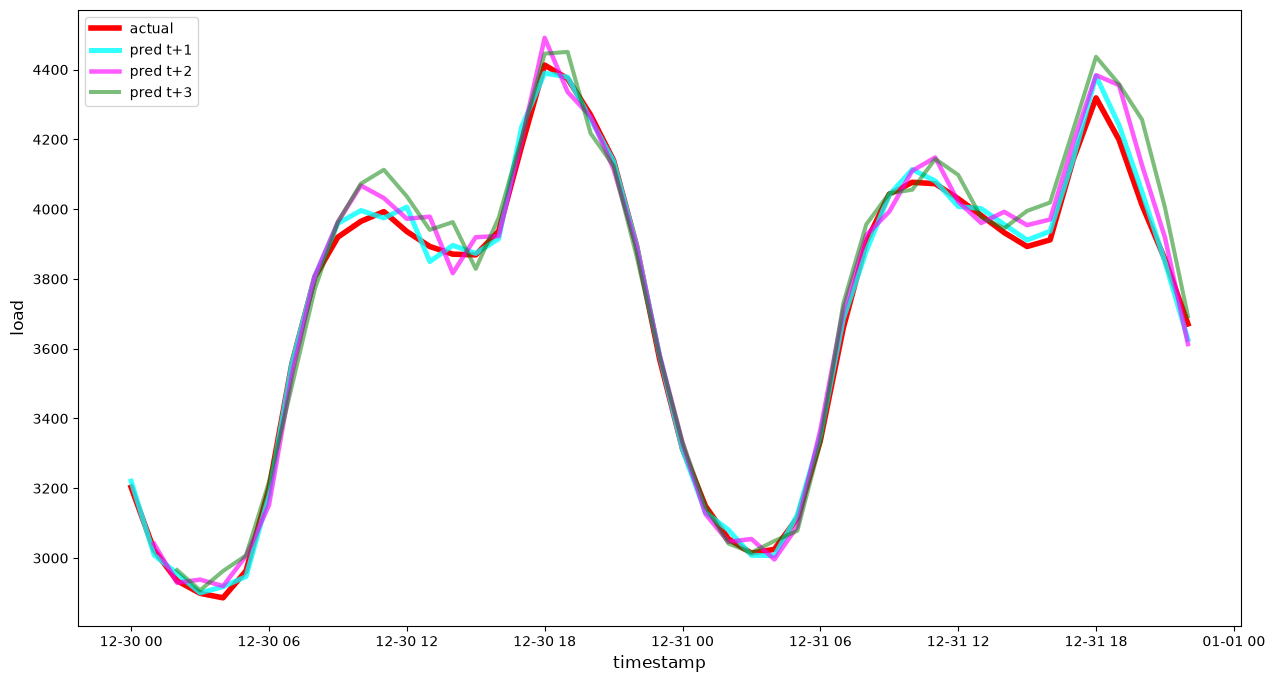

In [26]:
if(HORIZON == 1):
    ## Plotting single step forecast
    eval_df.plot(x='timestamp', y=['actual', 'prediction'], style=['r', 'b'], figsize=(15, 8))

else:
    colors = ['cyan', 'magenta', 'green']
    ## Plotting multi step forecast
    plot_df = eval_df[(eval_df.h=='t+1')][['timestamp', 'actual']]
    for t in range(1, HORIZON+1):
        plot_df['t+'+str(t)] = eval_df[(eval_df.h=='t+'+str(t))]['prediction'].values

    fig = plt.figure(figsize=(15, 8))
    ax = fig.add_subplot(111)
    ax.plot(plot_df['timestamp'], plot_df['actual'], color='red', linewidth=4.0)

    for t in range(1, HORIZON+1):
        x = plot_df['timestamp'][(t-1):]
        y = plot_df['t+'+str(t)][0:len(x)]
        ax.plot(x, y, color=colors[t-1], linewidth=4*math.pow(.9, t), alpha=math.pow(0.8, t))

    ax.legend(['actual', 'pred t+1', 'pred t+2', 'pred t+3'])

plt.xlabel('timestamp', fontsize=12)
plt.ylabel('load', fontsize=12)
plt.show()